# 2. Exploratory analysis

Two of the four questions are answered here:

* **Is there a commuter pattern**, with outer stations emptying in the morning and the city
  centre filling up?
* **How much does rain reduce usage?**

plus a look at which stations go empty or full, which sets up the modelling notebook.

In [1]:
import sys
sys.path.insert(0, "..")

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression

from bikes.features import PUBLIC_HOLIDAYS, add_time_features, load_stations
from bikes.train import load_grid
from bikes.weather import load_hourly

sns.set_theme(style="whitegrid")
grid = add_time_features(load_grid())
stations = load_stations()
grid["fill_ratio"] = grid["bikes"] / (grid["bikes"] + grid["docks"]).clip(lower=1)
grid["day_type"] = np.where((grid["is_weekend"] == 1) | (grid["is_holiday"] == 1), "weekend/holiday", "weekday")
print(f"{len(grid):,} rows")

8,733,281 rows


## 2.1 The daily rhythm of the whole network

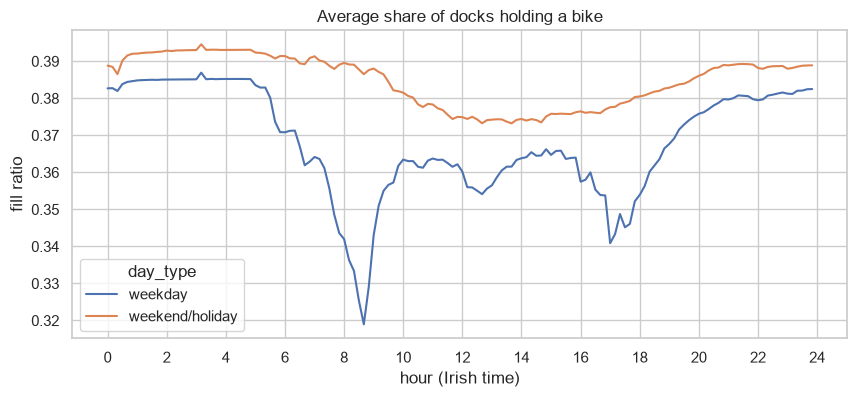

In [2]:
grid["slot"] = (grid["hour"] * 6).round() / 6
network = grid.groupby(["day_type", "slot"])["fill_ratio"].mean().unstack(0)
ax = network.plot(figsize=(10, 4))
ax.set(title="Average share of docks holding a bike", xlabel="hour (Irish time)", ylabel="fill ratio")
ax.set_xticks(range(0, 25, 2))
plt.show()

On weekdays there are two dips, at the morning and evening rush, when bikes are out on the
road instead of in docks. Weekends have one slow, shallow dip in the afternoon.

## 2.2 Commuter pattern: which stations fill and which empty?
For each station I take its average weekday fill ratio for every 10-minute slot. That gives a
144-number "daily profile" per station. K-means then groups stations with similar profiles.

(115, 144)


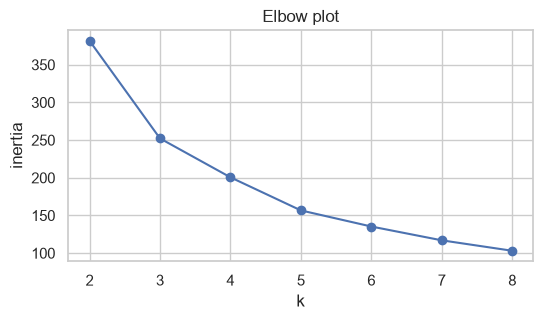

In [3]:
weekday = grid[grid["day_type"] == "weekday"]
profiles = weekday.pivot_table(index="station_id", columns="slot", values="fill_ratio", aggfunc="mean")
profiles = profiles.dropna()
print(profiles.shape)

inertia = {k: KMeans(k, n_init=10, random_state=0).fit(profiles).inertia_ for k in range(2, 9)}
pd.Series(inertia).plot(marker="o", figsize=(6, 3), title="Elbow plot", xlabel="k", ylabel="inertia")
plt.show()

In [4]:
K = 4
km = KMeans(K, n_init=10, random_state=0).fit(profiles)
labels = pd.Series(km.labels_, index=profiles.index, name="cluster")

# describe each cluster by its morning change (06:00 to 10:00), so the names come from the data
morning_change = profiles[10.0] - profiles[6.0]
summary = pd.DataFrame({"stations": labels.value_counts(),
                        "morning_change": morning_change.groupby(labels).mean(),
                        "avg_fill": profiles.mean(axis=1).groupby(labels).mean()}).sort_values("morning_change")
summary

,stations,morning_change,avg_fill
cluster,,,
2,27,-0.363561,0.548638
0,34,-0.104785,0.396491
3,28,0.008982,0.195721
1,26,0.470779,0.330846


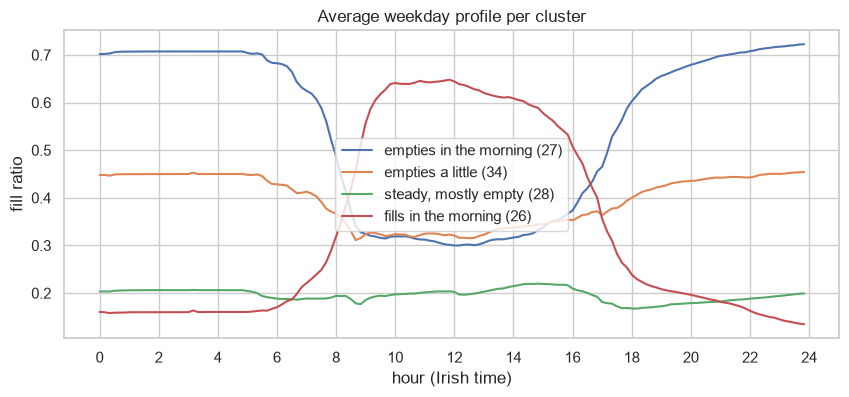

In [5]:
# name the clusters in order of their morning change, from "empties most" to "fills most"
ORDERED_NAMES = ["empties in the morning", "empties a little", "steady, mostly empty", "fills in the morning"]
names = pd.Series(ORDERED_NAMES, index=summary.index)
labels_named = labels.map(names)
fig, ax = plt.subplots(figsize=(10, 4))
for c in summary.index:
    profiles[labels == c].mean().plot(ax=ax, label=f"{names[c]} ({summary.loc[c, 'stations']})")
ax.set(title="Average weekday profile per cluster", xlabel="hour (Irish time)", ylabel="fill ratio")
ax.set_xticks(range(0, 25, 2))
ax.legend()
plt.show()

### Is it about distance from the centre?
If the commuter story is right, stations that fill up in the morning should be central and
stations that empty should be further out. O'Connell Bridge is used as the centre point.

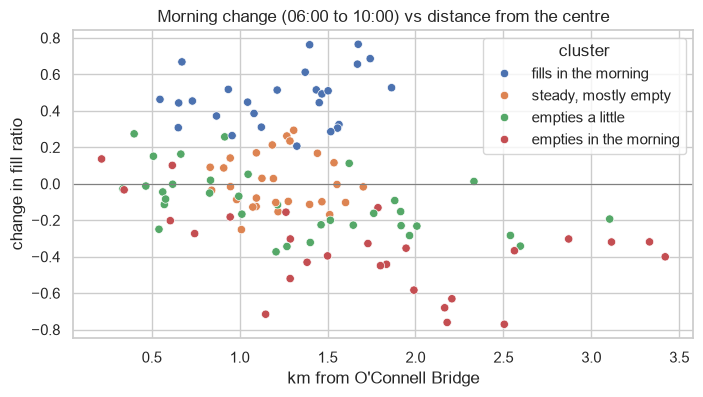

correlation, distance vs morning change: -0.37
correlation, east-west position vs morning change: 0.55


,km_from_centre,east_of_centre_km
cluster,,
empties a little,1.30,-0.51
empties in the morning,1.73,-0.91
fills in the morning,1.23,0.68
"steady, mostly empty",1.22,-0.47


In [6]:
CENTRE = (53.3472, -6.2592)  # O'Connell Bridge

def km_from_centre(lat, lon):
    dlat = np.radians(lat - CENTRE[0])
    dlon = np.radians(lon - CENTRE[1]) * np.cos(np.radians(CENTRE[0]))
    return 6371 * np.sqrt(dlat ** 2 + dlon ** 2)

st = stations.set_index("station_id").loc[profiles.index]
st["km_from_centre"] = km_from_centre(st["lat"], st["lon"])
st["morning_change"] = morning_change
st["cluster"] = labels_named
st["east_of_centre_km"] = (st["lon"] - CENTRE[1]) * 111 * np.cos(np.radians(CENTRE[0]))

fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=st, x="km_from_centre", y="morning_change", hue="cluster", ax=ax)
ax.axhline(0, color="grey", lw=0.8)
ax.set(title="Morning change (06:00 to 10:00) vs distance from the centre",
       xlabel="km from O'Connell Bridge", ylabel="change in fill ratio")
plt.show()
print("correlation, distance vs morning change:", round(st["km_from_centre"].corr(st["morning_change"]), 2))
print("correlation, east-west position vs morning change:", round(st["east_of_centre_km"].corr(st["morning_change"]), 2))
st.groupby("cluster")[["km_from_centre", "east_of_centre_km"]].mean().round(2)

In [7]:
# Interactive station map, kept for the final version and the presentation (not run in the draft).
# Call make_cluster_map(st).save("station_clusters_map.html") to produce it.
def make_cluster_map(st):
    """One dot per station, coloured by commuter cluster, with name and morning change on hover."""
    colours = {"fills in the morning": "red", "empties in the morning": "blue",
               "empties a little": "lightblue", "steady, mostly empty": "gray"}
    m = folium.Map(location=CENTRE, zoom_start=13)
    for sid, row in st.iterrows():
        folium.CircleMarker(
            [row["lat"], row["lon"]], radius=6, color=colours[row["cluster"]], fill=True, fill_opacity=0.8,
            tooltip=f"{row['name']}: {row['cluster']} ({row['morning_change']:+.2f})").add_to(m)
    return m

### Answer: yes, there is a clear commuter pattern, and it is driven by the train stations
* K-means splits the 115 stations into four weekday profiles. One group of 26 stations **fills
  up sharply in the morning**, gaining close to half its docks between 06:00 and 10:00, and
  empties again in the evening. Another 27 **empty in the morning**.
* The stations that fill are the **south-east office district**: Merrion Square, St Stephen's
  Green East, Earlsfort Terrace, Molesworth Street, Herbert Place.
* The stations that empty most are the **rail hubs**: Heuston (three stations, each losing
  60 to 75% of their docks' worth of bikes by 10:00), the Custom House / Talbot Street /
  Killarney Street area beside Connolly, and O'Connell Street. People arrive by train and ride
  the last stretch to work.
* East-west position explains this better than distance from the centre (correlation +0.55 vs
  -0.37), because Heuston is in the west and the offices are in the south-east.
* So the hypothesis "outer stations empty, centre fills" is only half right. The emptying is
  mostly at train stations, not in the suburbs, since the scheme does not reach the suburbs.

## 2.3 How much does rain reduce usage?
The data has no trip records, only dock counts. As a measure of **activity** I use the total
number of bikes taken or returned per hour across the network: the sum over stations of the
absolute change in bikes between 10-minute slots. It undercounts a little (a bike taken and
another returned at the same station in one slot cancel out), and van rebalancing is removed
by ignoring changes of 8+ bikes in one slot.

Rain falls more at some times of day and year than others, so comparing "rainy hours" with
"dry hours" directly would mix rain up with time of day and season. Instead I fit a regression
of log(activity) on rain, with hour-of-day x day-type and month as controls, so that the rain
coefficient compares like with like.

In [8]:
g = grid.sort_values(["station_id", "time"])
step = g.groupby("station_id")["bikes"].diff().abs()
g["moves"] = step.where(step < 8)
activity = g.groupby(g["time"].dt.floor("h"))["moves"].sum().rename("activity").reset_index()

weather = load_hourly()
hourly = activity.merge(weather, on="time", how="inner")
hourly = add_time_features(hourly)
hourly["hour_int"] = hourly["hour"].astype(int)
hourly["day_type"] = np.where((hourly["is_weekend"] == 1) | (hourly["is_holiday"] == 1), "weekend", "weekday")
hourly["month"] = hourly["time"].dt.month
hourly["rain_band"] = pd.cut(hourly["rain_mm"], [-0.01, 0.0, 0.5, 2, 100],
                             labels=["dry", "light (<0.5mm)", "moderate (0.5-2mm)", "heavy (>2mm)"])
# keep daytime hours: at 3am there is no one to put off
day = hourly[(hourly["hour_int"] >= 7) & (hourly["hour_int"] <= 21) & (hourly["activity"] > 0)].copy()
print(f"{len(day):,} daytime hours")
day["rain_band"].value_counts()

7,956 daytime hours


rain_band
dry                   6844
light (<0.5mm)         684
moderate (0.5-2mm)     331
heavy (>2mm)            97
Name: count, dtype: int64

In [9]:
X = pd.get_dummies(day[["rain_band"]], drop_first=True).join(
    pd.get_dummies(day["hour_int"].astype(str) + "_" + day["day_type"], prefix="hd", drop_first=True)).join(
    pd.get_dummies(day["month"], prefix="m", drop_first=True))
X["temp_c"] = day["temp_c"]
X["wind_ms"] = day["wind_ms"]
X = X.astype(float).fillna(X.mean())
reg = LinearRegression().fit(X, np.log(day["activity"]))
coefs = pd.Series(reg.coef_, index=X.columns)
effect = (np.exp(coefs[[c for c in X.columns if c.startswith("rain_band")] + ["temp_c", "wind_ms"]]) - 1) * 100
print("Change in activity compared with a dry hour at the same time of day, day type and month:")
effect.round(1).rename(lambda c: c.replace("rain_band_", "")).to_frame("% change")

Change in activity compared with a dry hour at the same time of day, day type and month:


,% change
light (<0.5mm),-12.1
moderate (0.5-2mm),-27.8
heavy (>2mm),-36.2
temp_c,1.5
wind_ms,-2.1


### Answer: rain cuts usage by about 12% to 36%, depending on how hard it rains
Compared with a dry hour at the same time of day, day type and month, activity drops by about
**12% in light rain**, **28% in moderate rain** and **36% in heavy rain**. Warmer hours are a bit
busier (around +1.5% per °C) and wind has a small negative effect. Heavy-rain hours are rare
(under 100 daytime hours in 18 months), so that number is the least certain of the three.

The chart below is the same comparison without any controls, split by hour. It is noisier,
but shows the drop is there at almost every hour of the day.

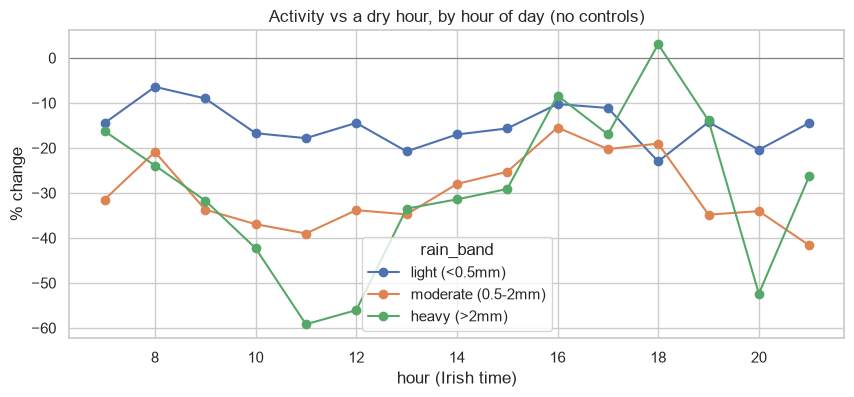

In [10]:
raw_ratio = day.groupby(["hour_int", "rain_band"], observed=True)["activity"].mean().unstack()
(raw_ratio.div(raw_ratio["dry"], axis=0) - 1).iloc[:, 1:].mul(100).plot(
    figsize=(10, 4), marker="o", title="Activity vs a dry hour, by hour of day (no controls)",
    xlabel="hour (Irish time)", ylabel="% change")
plt.axhline(0, color="grey", lw=0.8)
plt.show()

## 2.4 Which stations go empty or full?

Across the network a station is empty 10.8% and full 4.2% of the time


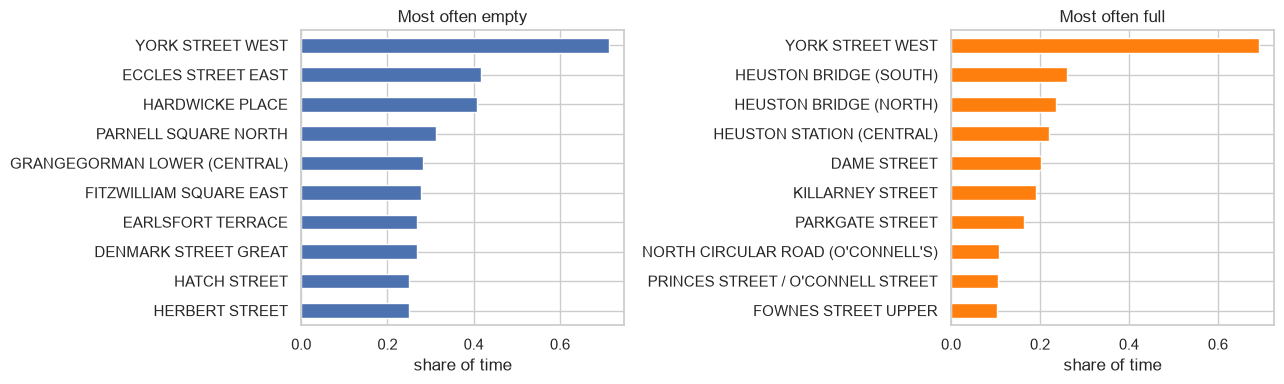

In [11]:
by_station = grid.groupby("station_id").agg(
    empty=("bikes", lambda s: (s == 0).mean()), full=("docks", lambda s: (s == 0).mean()))
by_station = by_station.join(stations.set_index("station_id")["name"])
print(f"Across the network a station is empty {(grid['bikes'] == 0).mean():.1%} "
      f"and full {(grid['docks'] == 0).mean():.1%} of the time")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_station.nlargest(10, "empty").set_index("name")["empty"].sort_values().plot.barh(ax=axes[0], title="Most often empty")
by_station.nlargest(10, "full").set_index("name")["full"].sort_values().plot.barh(ax=axes[1], title="Most often full", color="tab:orange")
for a in axes:
    a.set_xlabel("share of time")
    a.set_ylabel("")
plt.tight_layout()
plt.show()

Two different stories show up here:
* **Most often full:** the Heuston stations, Parkgate Street and Killarney Street. These are the
  rail-hub stations that empty every morning and refill every evening, and they sit full all
  night until the morning trains arrive.
* **Most often empty:** the north inner city (Eccles Street, Hardwicke Place, Parnell Square
  North, Grangegorman, Denmark Street) plus some of the south-east office stations (Earlsfort
  Terrace, Hatch Street, Herbert Street), which are empty every evening and night once the
  commuters have ridden home.

These are exactly the stations where an empty/full prediction is most useful.